
# Customer Analysis

## Objective

Analyze customer demographics, insurance participation, policy ownership, and customer-level claim behavior to identify meaningful portfolio segments and business opportunities.

## Analytical Scope

- Customer demographic segmentation
- Customer distribution by age, income, gender, and region
- Policy ownership and customer penetration
- Single-policy and multi-policy customers
- Customer claim participation and frequency
- Customer premium contribution
- Customer segmentation and business insights

## Data Source

MySQL Database: `insurance_claims_analytics`

**Primary Tables:** customers, policies, claims

**Supporting Tables:** risk_assessment, where required

## Methodology

Use Python, Pandas, NumPy, Matplotlib, and Seaborn to perform customer-level analysis.

Avoid repeating the basic distributions already examined in Exploratory Data Analysis.

Include relevant mathematical formulas, visualizations, interpretations, and business insights where necessary.

Formal statistical hypothesis testing will be performed separately in `11_Statistical_Analysis.ipynb`.


In [1]:

# Step 12.2 — Import Libraries and Connect to MySQL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

pd.set_option("display.max_columns", None)

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter MySQL password: "),
    host="localhost",
    port=3306,
    database="insurance_claims_analytics"
)

engine = create_engine(db_url)

with engine.connect() as connection:
    database = connection.execute(
        text("SELECT DATABASE()")
    ).scalar()

print("Connected Database:", database)
print("Libraries imported and MySQL connection successful.")


Connected Database: insurance_claims_analytics
Libraries imported and MySQL connection successful.


In [2]:

# Step 12.3 — Load Customer Analysis Tables

customers = pd.read_sql("SELECT * FROM customers", engine)
policies = pd.read_sql("SELECT * FROM policies", engine)
claims = pd.read_sql("SELECT * FROM claims", engine)

# Convert date columns
customers["Join_Date"] = pd.to_datetime(customers["Join_Date"])

policies["Start_Date"] = pd.to_datetime(policies["Start_Date"])
policies["End_Date"] = pd.to_datetime(policies["End_Date"])

claims["Claim_Date"] = pd.to_datetime(claims["Claim_Date"])

# Verify loaded records
print(f"Customers: {len(customers):,} rows")
print(f"Policies: {len(policies):,} rows")
print(f"Claims: {len(claims):,} rows")

print("\nCustomer analysis datasets loaded successfully.")


Customers: 10,000 rows
Policies: 15,000 rows
Claims: 25,000 rows

Customer analysis datasets loaded successfully.



### Customer Policy Ownership Analysis

Analyze the distribution of insurance policy ownership across the customer base, including customers without policies and customers holding multiple policies.

**Policy Ownership Rate:**

$$
\text{Policy Ownership Rate (\%)} =
\frac{\text{Customers with at Least One Policy}}
{\text{Total Customers}} \times 100
$$

**Multi-Policy Customer Rate:**

$$
\text{Multi-Policy Rate (\%)} =
\frac{\text{Customers with Two or More Policies}}
{\text{Total Customers}} \times 100
$$

These metrics help assess insurance participation and potential cross-selling opportunities.


In [3]:

# Step 12.4 — Customer Policy Ownership Analysis

policy_counts = (
    policies.groupby("Customer_ID")
    .size()
    .rename("Policy_Count")
)

customer_ownership = customers[
    ["Customer_ID"]
].merge(
    policy_counts,
    on="Customer_ID",
    how="left"
)

customer_ownership["Policy_Count"] = (
    customer_ownership["Policy_Count"]
    .fillna(0)
    .astype(int)
)

customer_ownership["Ownership_Group"] = (
    customer_ownership["Policy_Count"]
    .apply(lambda x: "4+" if x >= 4 else str(x))
)

ownership_summary = (
    customer_ownership["Ownership_Group"]
    .value_counts()
    .reindex(["0", "1", "2", "3", "4+"], fill_value=0)
    .rename_axis("Policies_Owned")
    .reset_index(name="Customers")
)

ownership_summary["Percentage"] = (
    ownership_summary["Customers"]
    / len(customers) * 100
).round(2)

display(ownership_summary)

print(
    "Policy Ownership Rate:",
    f"{(customer_ownership['Policy_Count'] >= 1).mean() * 100:.2f}%"
)

print(
    "Multi-Policy Customer Rate:",
    f"{(customer_ownership['Policy_Count'] >= 2).mean() * 100:.2f}%"
)


,Policies_Owned,Customers,Percentage
0,0,2280,22.80
1,1,3328,33.28
2,2,2430,24.30
3,3,1272,12.72
4,4+,690,6.90


Policy Ownership Rate: 77.20%
Multi-Policy Customer Rate: 43.92%



### Key Findings — Customer Policy Ownership

- **77.20%** of customers own at least one insurance policy.
- **22.80%** of customers have no recorded policies, representing a potential customer engagement opportunity.
- **43.92%** of all customers own two or more policies, indicating substantial multi-policy participation.
- Single-policy customers represent **33.28%** of the customer base.

**Business Interpretation:** Customers holding one policy may offer opportunities for relevant cross-selling, while customers without policies warrant further investigation. Actual cross-selling potential depends on customer eligibility, needs, and preferences.


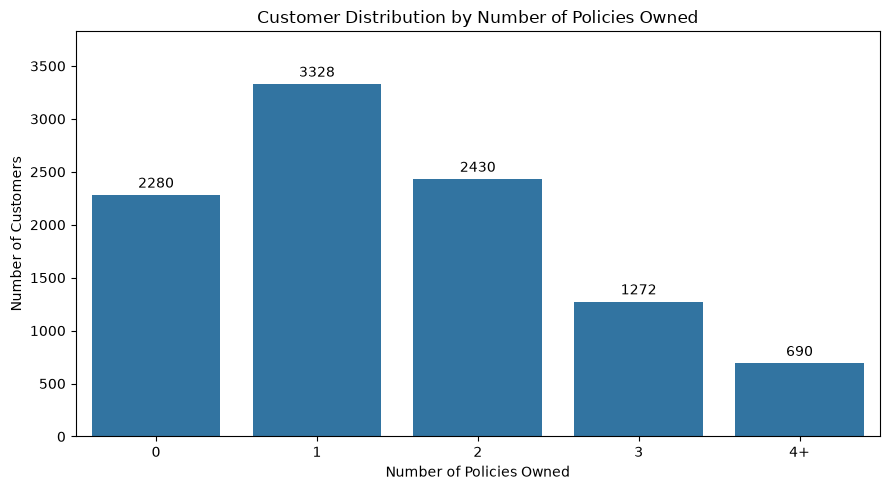

In [4]:

# Step 12.5 — Customer Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=ownership_summary,
    x="Policies_Owned",
    y="Customers"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Customer Distribution by Number of Policies Owned")
plt.xlabel("Number of Policies Owned")
plt.ylabel("Number of Customers")
plt.ylim(0, ownership_summary["Customers"].max() * 1.15)
plt.tight_layout()
plt.show()


In [5]:

# Step 12.6 — Customer Insurance Product Diversification

product_counts = (
    policies.groupby("Customer_ID")["Policy_Type"]
    .nunique()
    .rename("Product_Type_Count")
)

customer_diversification = customers[
    ["Customer_ID"]
].merge(
    product_counts,
    on="Customer_ID",
    how="left"
)

customer_diversification["Product_Type_Count"] = (
    customer_diversification["Product_Type_Count"]
    .fillna(0)
    .astype(int)
)

diversification_summary = (
    customer_diversification["Product_Type_Count"]
    .value_counts()
    .reindex(range(5), fill_value=0)
    .rename_axis("Distinct_Product_Types")
    .reset_index(name="Customers")
)

diversification_summary["Percentage"] = (
    diversification_summary["Customers"]
    / len(customers) * 100
).round(2)

display(diversification_summary)

print(
    "Multi-Product Customer Rate:",
    f"{(customer_diversification['Product_Type_Count'] >= 2).mean() * 100:.2f}%"
)


,Distinct_Product_Types,Customers,Percentage
0,0,2280,22.80
1,1,4185,41.85
2,2,2734,27.34
3,3,734,7.34
4,4,67,0.67


Multi-Product Customer Rate: 35.35%



### Key Findings — Insurance Product Diversification

- **35.35%** of customers own two or more distinct insurance product types.
- **41.85%** of customers own only one product type, representing a potential cross-selling segment.
- Only **0.67%** of customers own all four insurance product types.
- Multi-policy ownership (43.92%) exceeds multi-product ownership (35.35%), indicating that some customers hold multiple policies within the same product category.

**Business Insight:** Product diversification analysis helps identify opportunities to improve insurance product penetration through relevant cross-selling strategies.


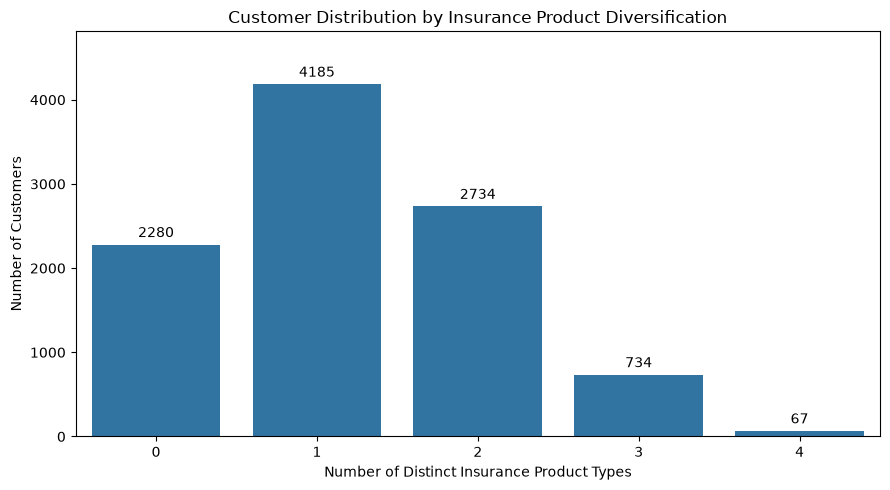

In [6]:

# Step 12.7 — Insurance Product Diversification Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=diversification_summary,
    x="Distinct_Product_Types",
    y="Customers"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Customer Distribution by Insurance Product Diversification")
plt.xlabel("Number of Distinct Insurance Product Types")
plt.ylabel("Number of Customers")

plt.ylim(0, diversification_summary["Customers"].max() * 1.15)

plt.tight_layout()
plt.show()


In [7]:

# Step 12.8 — Customer Claim Participation Analysis

customer_claim_counts = (
    claims.merge(
        policies[["Policy_ID", "Customer_ID"]],
        on="Policy_ID",
        how="left"
    )
    .groupby("Customer_ID")
    .size()
    .rename("Claim_Count")
)

customer_claim_analysis = customers[
    ["Customer_ID"]
].merge(
    customer_claim_counts,
    on="Customer_ID",
    how="left"
)

customer_claim_analysis["Claim_Count"] = (
    customer_claim_analysis["Claim_Count"]
    .fillna(0)
    .astype(int)
)

customer_claim_analysis["Claim_Participation"] = np.where(
    customer_claim_analysis["Claim_Count"] > 0,
    "With Claims",
    "Without Claims"
)

claim_participation_summary = (
    customer_claim_analysis["Claim_Participation"]
    .value_counts()
    .reindex(["With Claims", "Without Claims"], fill_value=0)
    .rename_axis("Claim_Participation")
    .reset_index(name="Customers")
)

claim_participation_summary["Percentage"] = (
    claim_participation_summary["Customers"]
    / len(customers) * 100
).round(2)

display(claim_participation_summary)

print(
    "Customer Claim Participation Rate:",
    f"{(customer_claim_analysis['Claim_Count'] > 0).mean() * 100:.2f}%"
)


,Claim_Participation,Customers,Percentage
0,With Claims,7007,70.07
1,Without Claims,2993,29.93


Customer Claim Participation Rate: 70.07%



### Key Findings — Customer Claim Participation

- **70.07%** of customers have submitted at least one recorded insurance claim.
- **29.93%** of customers have no recorded claims.
- Customer-level claim participation provides a foundation for investigating claim frequency and identifying high-claim customer segments.

**Business Interpretation:** Claim participation should be evaluated alongside policy ownership, customer exposure, and claim frequency before drawing conclusions about customer risk.


In [8]:

# Step 12.9 — Customer Claim Frequency Distribution

customer_claim_analysis["Claim_Frequency_Group"] = pd.cut(
    customer_claim_analysis["Claim_Count"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
)

claim_frequency_summary = (
    customer_claim_analysis["Claim_Frequency_Group"]
    .value_counts(sort=False)
    .rename_axis("Claims_Per_Customer")
    .reset_index(name="Customers")
)

claim_frequency_summary["Percentage"] = (
    claim_frequency_summary["Customers"]
    / len(customers) * 100
).round(2)

display(claim_frequency_summary)

print(
    "Average Claims per Customer:",
    round(customer_claim_analysis["Claim_Count"].mean(), 2)
)

print(
    "Maximum Claims by a Customer:",
    customer_claim_analysis["Claim_Count"].max()
)

print(
    "Customers with 4+ Claims:",
    (customer_claim_analysis["Claim_Count"] >= 4).sum()
)


,Claims_Per_Customer,Customers,Percentage
0,0,2993,29.93
1,1,1386,13.86
2,2,1529,15.29
3,3,1180,11.80
4,4+,2912,29.12


Average Claims per Customer: 2.5
Maximum Claims by a Customer: 18
Customers with 4+ Claims: 2912



### Key Findings — Customer Claim Frequency

- **29.93%** of customers have no recorded claims.
- **29.12%** of customers have submitted four or more claims.
- The average claim frequency is **2.50 claims per customer**, including customers with no claims.
- The maximum recorded claim count for an individual customer is **18**.

**Business Insight:** Customers with frequent claims represent an important segment for further investigation. However, high claim frequency alone does not establish fraud or elevated risk; policy exposure, coverage duration, and claim circumstances must also be considered.


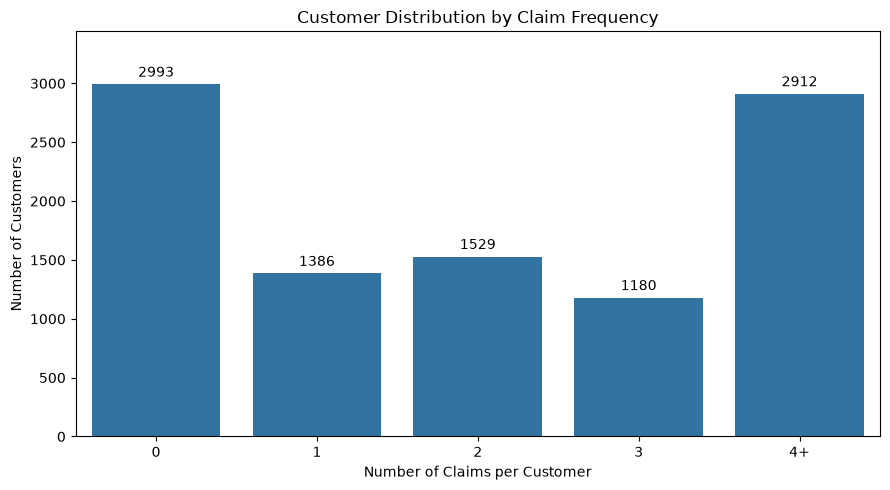

In [9]:

# Step 12.10 — Customer Claim Frequency Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=claim_frequency_summary,
    x="Claims_Per_Customer",
    y="Customers"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Customer Distribution by Claim Frequency")
plt.xlabel("Number of Claims per Customer")
plt.ylabel("Number of Customers")

plt.ylim(0, claim_frequency_summary["Customers"].max() * 1.15)

plt.tight_layout()
plt.show()



### Claim Concentration Analysis

**Claim Concentration Rate:**

$$
\text{Claim Concentration (\%)} =
\frac{\text{Claims from Customers with 4+ Claims}}
{\text{Total Claims}} \times 100
$$

This measures the share of recorded claims contributed by high-frequency customers.


In [10]:

# Step 12.11 — Claim Concentration Analysis

high_frequency_customers = customer_claim_analysis[
    customer_claim_analysis["Claim_Count"] >= 4
]

high_frequency_claims = high_frequency_customers["Claim_Count"].sum()

total_claims = customer_claim_analysis["Claim_Count"].sum()

claim_concentration = (
    high_frequency_claims / total_claims * 100
)

print("Total Claims:", f"{total_claims:,}")
print("High-Frequency Customers:", f"{len(high_frequency_customers):,}")
print("Claims from High-Frequency Customers:", f"{high_frequency_claims:,}")
print("Claim Concentration Rate:", f"{claim_concentration:.2f}%")


Total Claims: 25,000
High-Frequency Customers: 2,912
Claims from High-Frequency Customers: 17,016
Claim Concentration Rate: 68.06%



### Key Findings — Claim Concentration

- **2,912 customers (29.12%)** submitted four or more claims.
- These customers contributed **17,016 claims**, representing **68.06%** of total claim volume.
- The remaining customers contributed **31.94%** of claims.

**Business Insight:** Claim activity is concentrated among high-frequency customers. This segment may benefit from further investigation into policy exposure, claim severity, and risk characteristics. High claim frequency alone does not indicate fraudulent behavior.


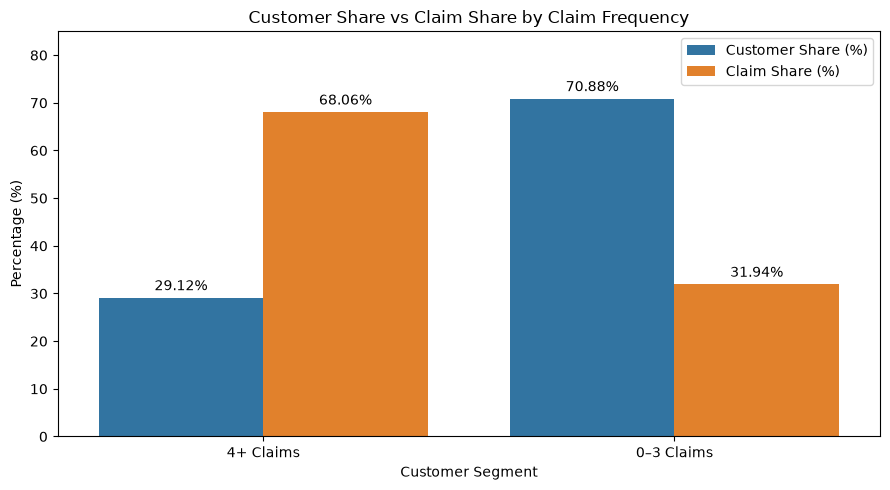

In [11]:

# Step 12.12 — Customer Share vs Claim Share

concentration_summary = pd.DataFrame({
    "Customer Segment": ["4+ Claims", "0–3 Claims"],
    "Customer Share (%)": [
        len(high_frequency_customers) / len(customers) * 100,
        (len(customers) - len(high_frequency_customers))
        / len(customers) * 100
    ],
    "Claim Share (%)": [
        claim_concentration,
        100 - claim_concentration
    ]
})

concentration_plot = concentration_summary.melt(
    id_vars="Customer Segment",
    var_name="Metric",
    value_name="Percentage"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=concentration_plot,
    x="Customer Segment",
    y="Percentage",
    hue="Metric"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Share vs Claim Share by Claim Frequency")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.ylim(0, 85)
plt.legend(title="")
plt.tight_layout()
plt.show()


In [12]:

# Step 12.13 — Customer Premium Contribution Analysis

customer_premiums = (
    policies.groupby("Customer_ID")["Annual_Premium"]
    .sum()
    .rename("Total_Annual_Premium")
)

customer_premium_analysis = customers[
    ["Customer_ID"]
].merge(
    customer_premiums,
    on="Customer_ID",
    how="left"
)

customer_premium_analysis["Total_Annual_Premium"] = (
    customer_premium_analysis["Total_Annual_Premium"]
    .fillna(0)
)

premium_summary = pd.DataFrame({
    "Metric": [
        "Total Annual Policy Premium",
        "Average Premium per Customer",
        "Median Premium per Customer",
        "Maximum Customer Premium",
        "Customers with Premium"
    ],
    "Value": [
        customer_premium_analysis["Total_Annual_Premium"].sum(),
        customer_premium_analysis["Total_Annual_Premium"].mean(),
        customer_premium_analysis["Total_Annual_Premium"].median(),
        customer_premium_analysis["Total_Annual_Premium"].max(),
        (customer_premium_analysis["Total_Annual_Premium"] > 0).sum()
    ]
})

display(premium_summary.round(2))


,Metric,Value
0,Total Annual Policy Premium,3.325029e+08
1,Average Premium per Customer,3.325029e+04
2,Median Premium per Customer,2.450932e+04
3,Maximum Customer Premium,2.488215e+05
4,Customers with Premium,7.720000e+03



### Key Findings — Customer Premium Contribution

- Total recorded annual policy premiums are approximately **₹332.50 million**.
- Average annual premium per customer is approximately **₹33,250**, including customers without policies.
- Median annual premium per customer is approximately **₹24,509**, lower than the average, suggesting a right-skewed customer premium distribution.
- **7,720 customers** contribute recorded annual policy premiums.

**Business Insight:** Customer-level premium analysis helps identify portfolio value concentration and potential opportunities for customer retention and product expansion.


In [13]:

# Step 12.14 — Customer Premium Concentration Analysis

premium_ranked = (
    customer_premium_analysis
    .sort_values("Total_Annual_Premium", ascending=False)
    .reset_index(drop=True)
)

premium_ranked["Customer_Rank"] = np.arange(1, len(premium_ranked) + 1)

premium_ranked["Premium_Segment"] = pd.cut(
    premium_ranked["Customer_Rank"],
    bins=[0, 100, 500, 1000, len(premium_ranked)],
    labels=["Top 1%", "Next 4%", "Next 5%", "Remaining 90%"]
)

premium_concentration = (
    premium_ranked.groupby(
        "Premium_Segment",
        observed=True
    )
    .agg(
        Customers=("Customer_ID", "count"),
        Annual_Premium=("Total_Annual_Premium", "sum")
    )
    .reset_index()
)

premium_concentration["Premium_Share_Percent"] = (
    premium_concentration["Annual_Premium"]
    / premium_concentration["Annual_Premium"].sum() * 100
).round(2)

display(premium_concentration.round(2))


,Premium_Segment,Customers,Annual_Premium,Premium_Share_Percent
0,Top 1%,100,1.749810e+07,5.26
1,Next 4%,400,4.735369e+07,14.24
2,Next 5%,500,4.420537e+07,13.29
3,Remaining 90%,9000,2.234458e+08,67.20



### Key Findings — Customer Premium Concentration

- The top **1%** of customers contribute **5.26%** of total annual policy premiums.
- The next **4%** contribute **14.24%**, while the next **5%** contribute **13.29%**.
- Collectively, the top **10%** of customers contribute approximately **32.80%** of total annual policy premiums.
- The remaining **90%** contribute approximately **67.20%**.

**Business Insight:** Premium contributions are moderately concentrated among higher-premium customers. Understanding these segments can support targeted retention strategies and customer portfolio management.

**Note:** Premium contributions represent recorded annual policy premiums, not confirmed premium collections.


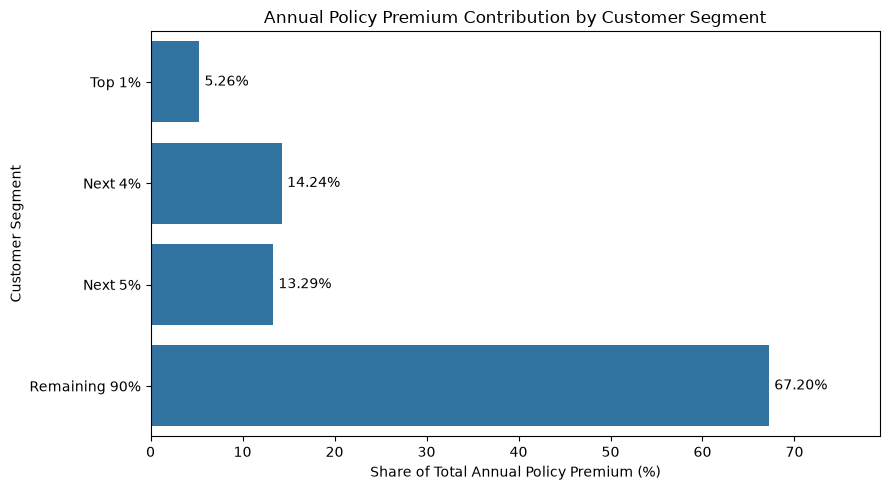

In [14]:

# Step 12.15 — Customer Premium Concentration Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=premium_concentration,
    x="Premium_Share_Percent",
    y="Premium_Segment"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Annual Policy Premium Contribution by Customer Segment")
plt.xlabel("Share of Total Annual Policy Premium (%)")
plt.ylabel("Customer Segment")

plt.xlim(0, premium_concentration["Premium_Share_Percent"].max() * 1.18)

plt.tight_layout()
plt.show()


In [15]:

# Step 12.16 — Claim Participation by Policy Ownership

ownership_claim_analysis = customer_ownership[
    ["Customer_ID", "Policy_Count", "Ownership_Group"]
].merge(
    customer_claim_analysis[["Customer_ID", "Claim_Count"]],
    on="Customer_ID",
    how="left"
)

ownership_claim_summary = (
    ownership_claim_analysis
    .groupby("Ownership_Group")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Claims=("Claim_Count", lambda x: (x > 0).sum()),
        Total_Claims=("Claim_Count", "sum")
    )
    .reindex(["0", "1", "2", "3", "4+"])
    .reset_index()
)

ownership_claim_summary["Claim_Participation_Rate"] = (
    ownership_claim_summary["Customers_With_Claims"]
    / ownership_claim_summary["Total_Customers"] * 100
).round(2)

ownership_claim_summary["Average_Claims_Per_Customer"] = (
    ownership_claim_summary["Total_Claims"]
    / ownership_claim_summary["Total_Customers"]
).round(2)

display(ownership_claim_summary)


,Ownership_Group,Total_Customers,Customers_With_Claims,Total_Claims,Claim_Participation_Rate,Average_Claims_Per_Customer
0,0,2280,0,0,0.00,0.00
1,1,3328,2707,5501,81.34,1.65
2,2,2430,2349,8058,96.67,3.32
3,3,1272,1261,6401,99.14,5.03
4,4+,690,690,5040,100.00,7.30



### Key Findings — Claim Participation by Policy Ownership

- Claim participation increases from **81.34%** among single-policy customers to **100%** among customers holding four or more policies.
- Average recorded claims increase from **1.65** for single-policy customers to **7.30** for customers with four or more policies.
- Customers without recorded policies have no linked claims.

**Business Insight:** Multi-policy customers account for greater historical claim activity, potentially reflecting greater insurance exposure. Exposure-adjusted claim frequency would be needed for a fair comparison of underlying risk.


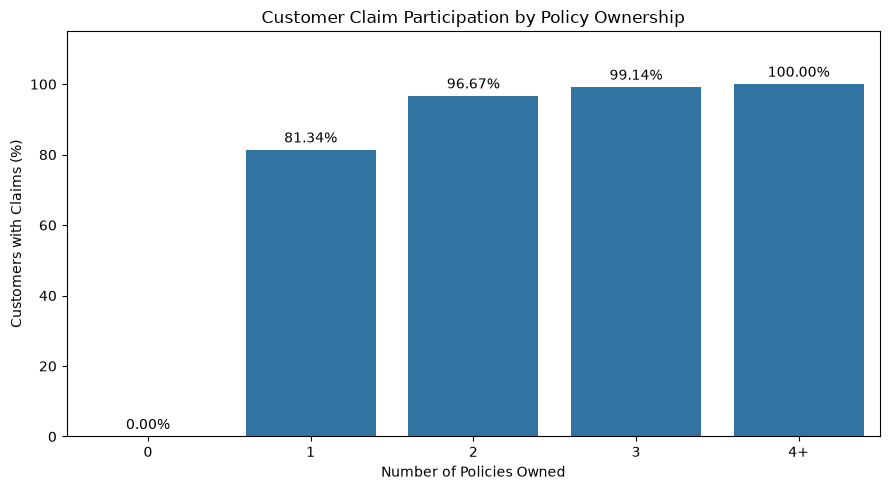

In [16]:

# Step 12.17 — Claim Participation by Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=ownership_claim_summary,
    x="Ownership_Group",
    y="Claim_Participation_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Claim Participation by Policy Ownership")
plt.xlabel("Number of Policies Owned")
plt.ylabel("Customers with Claims (%)")

plt.ylim(0, 115)

plt.tight_layout()
plt.show()


In [17]:

# Step 12.18 — Claim Participation by Product Diversification

diversification_claim_analysis = customer_diversification[
    ["Customer_ID", "Product_Type_Count"]
].merge(
    customer_claim_analysis[["Customer_ID", "Claim_Count"]],
    on="Customer_ID",
    how="left"
)

diversification_claim_summary = (
    diversification_claim_analysis
    .groupby("Product_Type_Count")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Claims=("Claim_Count", lambda x: (x > 0).sum()),
        Total_Claims=("Claim_Count", "sum")
    )
    .reset_index()
)

diversification_claim_summary["Participation_Rate"] = (
    diversification_claim_summary["Customers_With_Claims"]
    / diversification_claim_summary["Total_Customers"] * 100
).round(2)

diversification_claim_summary["Avg_Claims_Per_Customer"] = (
    diversification_claim_summary["Total_Claims"]
    / diversification_claim_summary["Total_Customers"]
).round(2)

display(diversification_claim_summary)


,Product_Type_Count,Total_Customers,Customers_With_Claims,Total_Claims,Participation_Rate,Avg_Claims_Per_Customer
0,0,2280,0,0,0.00,0.00
1,1,4185,3546,8728,84.73,2.09
2,2,2734,2662,11241,97.37,4.11
3,3,734,732,4512,99.73,6.15
4,4,67,67,519,100.00,7.75



### Key Findings — Claim Participation by Product Diversification

- Claim participation increases from **84.73%** among single-product customers to **100%** among customers holding all four product types.
- Average recorded claims increase from **2.09** for single-product customers to **7.75** for customers holding four distinct product types.
- Customers with multiple insurance product types demonstrate greater historical claim activity.

**Business Insight:** Product diversification is associated with higher recorded claim participation. However, this relationship may reflect differences in policy exposure and coverage rather than higher underlying customer risk.


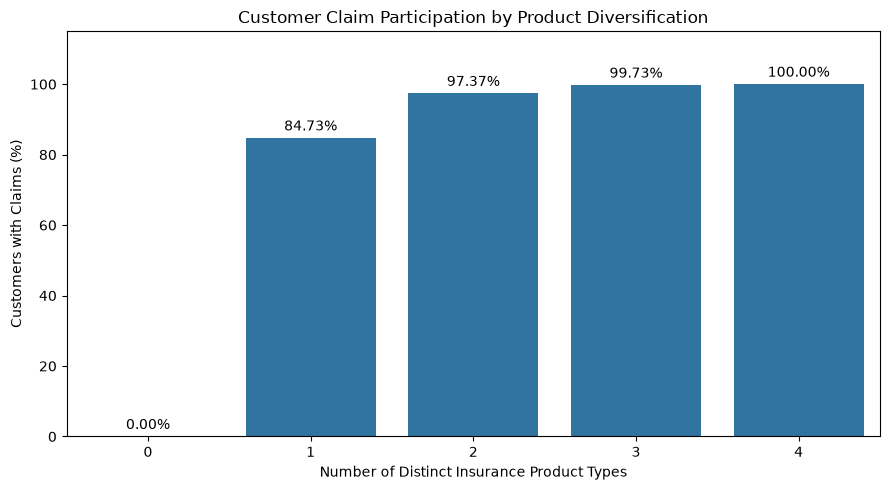

In [18]:

# Step 12.19 — Claim Participation by Product Diversification

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=diversification_claim_summary,
    x="Product_Type_Count",
    y="Participation_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Claim Participation by Product Diversification")
plt.xlabel("Number of Distinct Insurance Product Types")
plt.ylabel("Customers with Claims (%)")

plt.ylim(0, 115)

plt.tight_layout()
plt.show()


In [19]:

# Step 12.20 — Customer Segmentation by Age and Policy Ownership

age_policy_analysis = customers[
    ["Customer_ID", "Age"]
].merge(
    customer_ownership[["Customer_ID", "Policy_Count"]],
    on="Customer_ID",
    how="left"
)

age_policy_analysis["Age_Group"] = pd.cut(
    age_policy_analysis["Age"],
    bins=[17, 30, 40, 50, 60, 80],
    labels=["18-30", "31-40", "41-50", "51-60", "61-80"]
)

age_policy_summary = (
    age_policy_analysis
    .groupby("Age_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Policies=("Policy_Count", lambda x: (x > 0).sum()),
        Total_Policies=("Policy_Count", "sum")
    )
    .reset_index()
)

age_policy_summary["Ownership_Rate"] = (
    age_policy_summary["Customers_With_Policies"]
    / age_policy_summary["Total_Customers"] * 100
).round(2)

age_policy_summary["Avg_Policies_Per_Customer"] = (
    age_policy_summary["Total_Policies"]
    / age_policy_summary["Total_Customers"]
).round(2)

display(age_policy_summary)


,Age_Group,Total_Customers,Customers_With_Policies,Total_Policies,Ownership_Rate,Avg_Policies_Per_Customer
0,18-30,2087,1611,3146,77.19,1.51
1,31-40,1607,1252,2369,77.91,1.47
2,41-50,1630,1271,2504,77.98,1.54
3,51-60,1572,1203,2310,76.53,1.47
4,61-80,3104,2383,4671,76.77,1.50



### Key Findings — Age-Based Policy Ownership

- Customers aged **41–50** have the highest policy ownership rate at **77.98%**.
- Customers aged **51–60** have the lowest ownership rate at **76.53%**.
- Ownership rates vary by only **1.45 percentage points** across age groups.
- Average policies per customer range from **1.47 to 1.54**, indicating relatively consistent policy ownership.

**Business Insight:** Age groups show similar insurance participation, suggesting that age alone may not be a strong differentiator of policy ownership in this dataset.


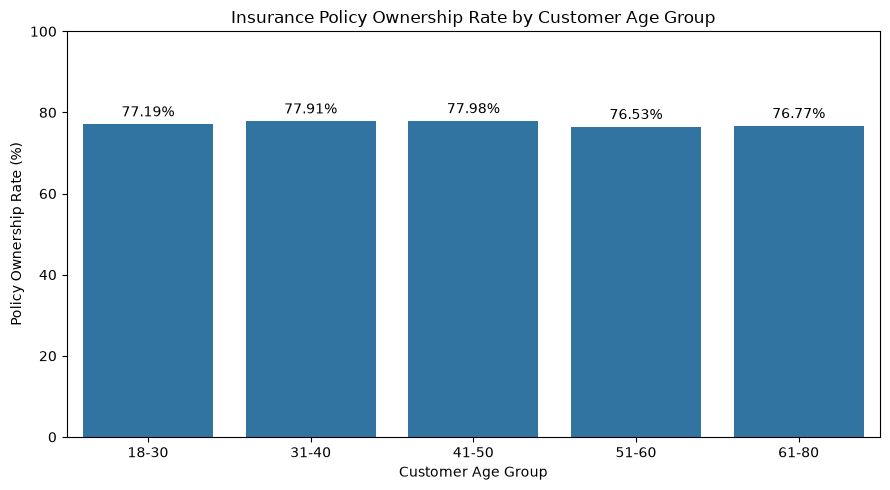

In [20]:

# Step 12.21 — Age-Based Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_policy_summary,
    x="Age_Group",
    y="Ownership_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Insurance Policy Ownership Rate by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Policy Ownership Rate (%)")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [21]:

# Step 12.22 — Customer Policy Ownership by Income Group

income_policy_analysis = customers[
    ["Customer_ID", "Annual_Income"]
].merge(
    customer_ownership[["Customer_ID", "Policy_Count"]],
    on="Customer_ID",
    how="left"
)

# Create income groups using customer income quartiles
income_policy_analysis["Income_Group"] = pd.qcut(
    income_policy_analysis["Annual_Income"],
    q=4,
    labels=["Q1 - Low", "Q2 - Lower Middle",
            "Q3 - Upper Middle", "Q4 - High"]
)

income_policy_summary = (
    income_policy_analysis
    .groupby("Income_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Policies=("Policy_Count", lambda x: (x > 0).sum()),
        Total_Policies=("Policy_Count", "sum")
    )
    .reset_index()
)

income_policy_summary["Ownership_Rate"] = (
    income_policy_summary["Customers_With_Policies"]
    / income_policy_summary["Total_Customers"] * 100
).round(2)

income_policy_summary["Avg_Policies_Per_Customer"] = (
    income_policy_summary["Total_Policies"]
    / income_policy_summary["Total_Customers"]
).round(2)

display(income_policy_summary)


,Income_Group,Total_Customers,Customers_With_Policies,Total_Policies,Ownership_Rate,Avg_Policies_Per_Customer
0,Q1 - Low,2500,1950,3791,78.00,1.52
1,Q2 - Lower Middle,2500,1913,3702,76.52,1.48
2,Q3 - Upper Middle,2500,1924,3758,76.96,1.50
3,Q4 - High,2500,1933,3749,77.32,1.50



### Key Findings — Income-Based Policy Ownership

- The lowest-income quartile (Q1) has the highest policy ownership rate at **78.00%**.
- The second income quartile (Q2) has the lowest ownership rate at **76.52%**.
- Ownership rates differ by only **1.48 percentage points** across income quartiles.
- Average policies per customer range from **1.48 to 1.52**.

**Business Insight:** Policy ownership is relatively consistent across income groups. Income alone does not appear to be a strong differentiator of insurance participation in this dataset.

**Note:** Income groups are dataset-specific quartiles, not standardized income classifications.


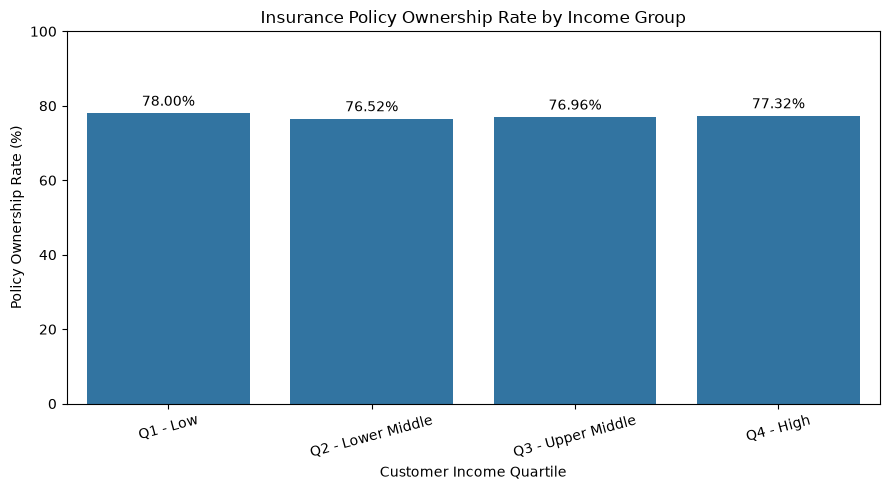

In [22]:

# Step 12.23 — Income-Based Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=income_policy_summary,
    x="Income_Group",
    y="Ownership_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Insurance Policy Ownership Rate by Income Group")
plt.xlabel("Customer Income Quartile")
plt.ylabel("Policy Ownership Rate (%)")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [23]:

# Step 12.24 — Regional Customer Policy Ownership Analysis

regional_policy_analysis = customers[
    ["Customer_ID", "Region"]
].merge(
    customer_ownership[["Customer_ID", "Policy_Count"]],
    on="Customer_ID",
    how="left"
)

regional_policy_summary = (
    regional_policy_analysis
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Policies=("Policy_Count", lambda x: (x > 0).sum()),
        Total_Policies=("Policy_Count", "sum")
    )
    .reset_index()
)

regional_policy_summary["Ownership_Rate"] = (
    regional_policy_summary["Customers_With_Policies"]
    / regional_policy_summary["Total_Customers"] * 100
).round(2)

regional_policy_summary["Avg_Policies_Per_Customer"] = (
    regional_policy_summary["Total_Policies"]
    / regional_policy_summary["Total_Customers"]
).round(2)

regional_policy_summary = regional_policy_summary.sort_values(
    "Ownership_Rate",
    ascending=False
)

display(regional_policy_summary)


,Region,Total_Customers,Customers_With_Policies,Total_Policies,Ownership_Rate,Avg_Policies_Per_Customer
1,East,1960,1533,2994,78.21,1.53
0,Central,2018,1565,3006,77.55,1.49
3,South,1981,1523,2933,76.88,1.48
4,West,2029,1559,3048,76.84,1.50
2,North,2012,1540,3019,76.54,1.50



### Key Findings — Regional Policy Ownership

- The **East** region has the highest policy ownership rate at **78.21%**.
- The **North** region has the lowest ownership rate at **76.54%**.
- Regional ownership rates vary by only **1.67 percentage points**.
- Average policies per customer range from **1.48 to 1.53** across regions.

**Business Insight:** Insurance participation is relatively balanced across regions. Regional differences are small, suggesting that further customer-level factors should be considered before prioritizing geographic expansion or targeted campaigns.


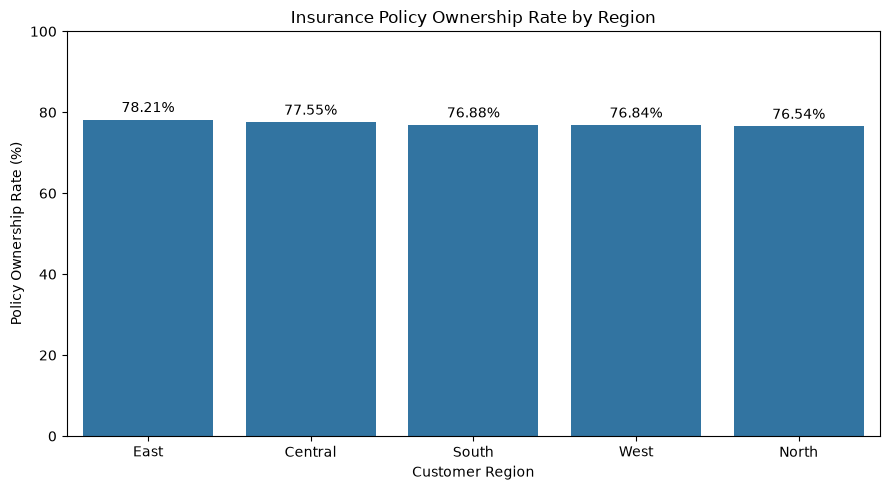

In [24]:

# Step 12.25 — Regional Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=regional_policy_summary,
    x="Region",
    y="Ownership_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Insurance Policy Ownership Rate by Region")
plt.xlabel("Customer Region")
plt.ylabel("Policy Ownership Rate (%)")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [25]:

# Step 12.26 — Regional Customer Claim Participation Analysis

regional_claim_analysis = customers[
    ["Customer_ID", "Region"]
].merge(
    customer_claim_analysis[["Customer_ID", "Claim_Count"]],
    on="Customer_ID",
    how="left"
)

regional_claim_summary = (
    regional_claim_analysis
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Claims=("Claim_Count", lambda x: (x > 0).sum()),
        Total_Claims=("Claim_Count", "sum")
    )
    .reset_index()
)

regional_claim_summary["Claim_Participation_Rate"] = (
    regional_claim_summary["Customers_With_Claims"]
    / regional_claim_summary["Total_Customers"] * 100
).round(2)

regional_claim_summary["Avg_Claims_Per_Customer"] = (
    regional_claim_summary["Total_Claims"]
    / regional_claim_summary["Total_Customers"]
).round(2)

regional_claim_summary = regional_claim_summary.sort_values(
    "Claim_Participation_Rate",
    ascending=False
)

display(regional_claim_summary)


,Region,Total_Customers,Customers_With_Claims,Total_Claims,Claim_Participation_Rate,Avg_Claims_Per_Customer
1,East,1960,1404,4997,71.63,2.55
4,West,2029,1419,5035,69.94,2.48
3,South,1981,1381,4861,69.71,2.45
2,North,2012,1401,5062,69.63,2.52
0,Central,2018,1402,5045,69.47,2.50



### Key Findings — Regional Customer Claim Participation

- The East region has the highest claim participation rate at **71.63%**.
- The Central region has the lowest participation rate at **69.47%**.
- Regional participation rates differ by only **2.16 percentage points**.
- Average recorded claims per customer range from **2.45 to 2.55**.

**Business Insight:** Historical claim participation is relatively consistent across regions. Regional differences alone do not provide sufficient evidence of higher underlying insurance risk.


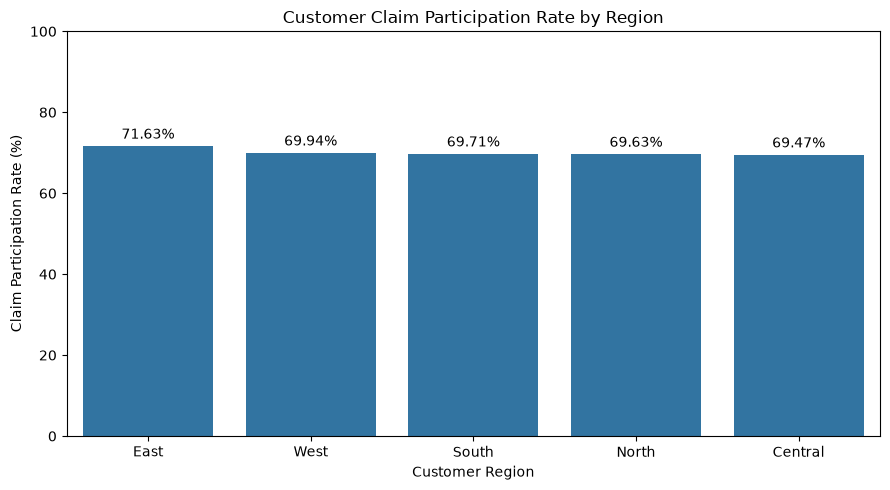

In [26]:

# Step 12.27 — Regional Claim Participation Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=regional_claim_summary,
    x="Region",
    y="Claim_Participation_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Claim Participation Rate by Region")
plt.xlabel("Customer Region")
plt.ylabel("Claim Participation Rate (%)")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [27]:

# Step 12.28 — Customer Claim Participation by Age Group

age_claim_analysis = customers[
    ["Customer_ID", "Age"]
].merge(
    customer_claim_analysis[["Customer_ID", "Claim_Count"]],
    on="Customer_ID",
    how="left"
)

age_claim_analysis["Age_Group"] = pd.cut(
    age_claim_analysis["Age"],
    bins=[17, 30, 40, 50, 60, 80],
    labels=["18-30", "31-40", "41-50", "51-60", "61-80"]
)

age_claim_summary = (
    age_claim_analysis
    .groupby("Age_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Claims=("Claim_Count", lambda x: (x > 0).sum()),
        Total_Claims=("Claim_Count", "sum")
    )
    .reset_index()
)

age_claim_summary["Claim_Participation_Rate"] = (
    age_claim_summary["Customers_With_Claims"]
    / age_claim_summary["Total_Customers"] * 100
).round(2)

age_claim_summary["Avg_Claims_Per_Customer"] = (
    age_claim_summary["Total_Claims"]
    / age_claim_summary["Total_Customers"]
).round(2)

display(age_claim_summary)


,Age_Group,Total_Customers,Customers_With_Claims,Total_Claims,Claim_Participation_Rate,Avg_Claims_Per_Customer
0,18-30,2087,1472,5196,70.53,2.49
1,31-40,1607,1124,3931,69.94,2.45
2,41-50,1630,1167,4207,71.60,2.58
3,51-60,1572,1086,3827,69.08,2.43
4,61-80,3104,2158,7839,69.52,2.53



### Key Findings — Age-Based Claim Participation

- Customers aged **41–50** have the highest historical claim participation rate at **71.60%**.
- Customers aged **51–60** have the lowest participation rate at **69.08%**.
- Claim participation varies by only **2.52 percentage points** across age groups.
- Average recorded claims per customer range from **2.43 to 2.58**.

**Business Insight:** Historical claim participation is relatively consistent across age groups. Age alone does not appear to strongly differentiate claim participation in this dataset. Policy exposure and coverage duration should be considered before interpreting customer risk.


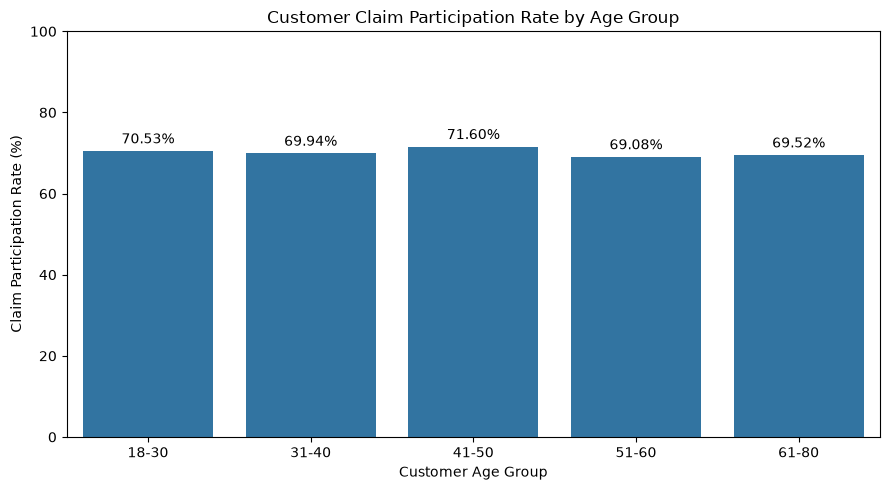

In [28]:

# Step 12.29 — Age-Based Claim Participation Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_claim_summary,
    x="Age_Group",
    y="Claim_Participation_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Claim Participation Rate by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Claim Participation Rate (%)")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [29]:

# Step 12.30 — Customer Claim Participation by Income Group

income_claim_analysis = income_policy_analysis[
    ["Customer_ID", "Income_Group"]
].merge(
    customer_claim_analysis[["Customer_ID", "Claim_Count"]],
    on="Customer_ID",
    how="left"
)

income_claim_summary = (
    income_claim_analysis
    .groupby("Income_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Customers_With_Claims=("Claim_Count", lambda x: (x > 0).sum()),
        Total_Claims=("Claim_Count", "sum")
    )
    .reset_index()
)

income_claim_summary["Claim_Participation_Rate"] = (
    income_claim_summary["Customers_With_Claims"]
    / income_claim_summary["Total_Customers"] * 100
).round(2)

income_claim_summary["Avg_Claims_Per_Customer"] = (
    income_claim_summary["Total_Claims"]
    / income_claim_summary["Total_Customers"]
).round(2)

display(income_claim_summary)


,Income_Group,Total_Customers,Customers_With_Claims,Total_Claims,Claim_Participation_Rate,Avg_Claims_Per_Customer
0,Q1 - Low,2500,1766,6299,70.64,2.52
1,Q2 - Lower Middle,2500,1733,6220,69.32,2.49
2,Q3 - Upper Middle,2500,1754,6205,70.16,2.48
3,Q4 - High,2500,1754,6276,70.16,2.51



### Key Findings — Income-Based Claim Participation

- The lowest-income quartile (Q1) has the highest claim participation rate at **70.64%**.
- The second income quartile (Q2) has the lowest participation rate at **69.32%**.
- Claim participation varies by only **1.32 percentage points** across income quartiles.
- Average recorded claims per customer range from **2.48 to 2.52**.

**Business Insight:** Historical claim participation is relatively consistent across income groups. Income alone does not appear to strongly differentiate claim participation in this dataset. Policy exposure should be considered when comparing customer risk.


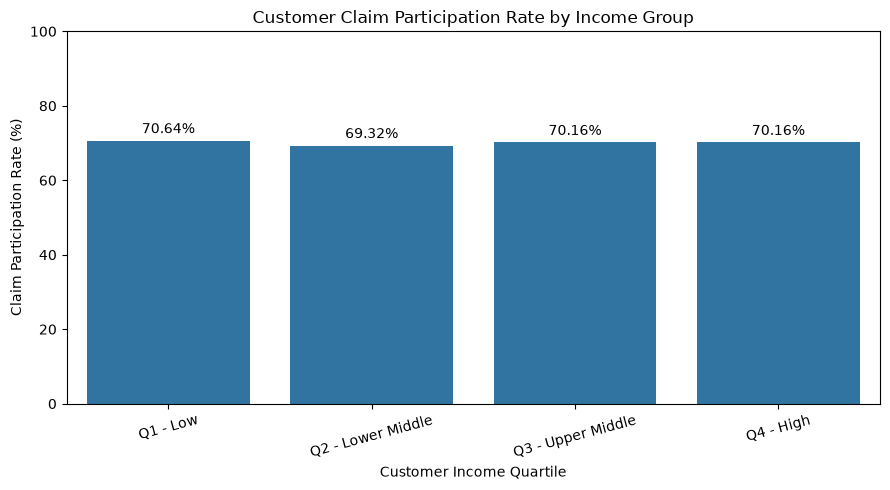

In [30]:

# Step 12.31 — Income-Based Claim Participation Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=income_claim_summary,
    x="Income_Group",
    y="Claim_Participation_Rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Claim Participation Rate by Income Group")
plt.xlabel("Customer Income Quartile")
plt.ylabel("Claim Participation Rate (%)")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [34]:

# Step 12.32 — Customer Premium Contribution by Age Group

age_premium_analysis = customers[
    ["Customer_ID", "Age"]
].merge(
    customer_premium_analysis[
        ["Customer_ID", "Total_Annual_Premium"]
    ],
    on="Customer_ID",
    how="left"
)

age_premium_analysis["Age_Group"] = pd.cut(
    age_premium_analysis["Age"],
    bins=[17, 30, 40, 50, 60, 80],
    labels=["18-30", "31-40", "41-50", "51-60", "61-80"]
)

age_premium_summary = (
    age_premium_analysis
    .groupby("Age_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Total_Annual_Premium=("Total_Annual_Premium", "sum"),
        Avg_Premium_Per_Customer=("Total_Annual_Premium", "mean")
    )
    .reset_index()
)

age_premium_summary["Premium_Share_Percent"] = (
    age_premium_summary["Total_Annual_Premium"]
    / age_premium_summary["Total_Annual_Premium"].sum() * 100
).round(2)

# Display results without requiring jinja2
display(age_premium_summary.round(2))


,Age_Group,Total_Customers,Total_Annual_Premium,Avg_Premium_Per_Customer,Premium_Share_Percent
0,18-30,2087,6.985899e+07,33473.40,21.01
1,31-40,1607,5.284652e+07,32885.20,15.89
2,41-50,1630,5.639402e+07,34597.56,16.96
3,51-60,1572,5.139728e+07,32695.47,15.46
4,61-80,3104,1.020061e+08,32862.80,30.68



### Key Findings — Age-Based Premium Contribution

- Customers aged **61–80** contribute the highest share of recorded annual policy premiums at **30.68%**.
- Customers aged **51–60** contribute the lowest share at **15.46%**.
- Customers aged **41–50** have the highest average annual premium per customer at **₹34,597.56**.
- Average annual premiums per customer are relatively similar across age groups.

**Business Insight:** Differences in total premium contribution are influenced by customer population size. Average premium per customer provides a more comparable measure of customer portfolio value across age groups.

**Note:** These figures represent recorded annual policy premiums, not actual premium collections.


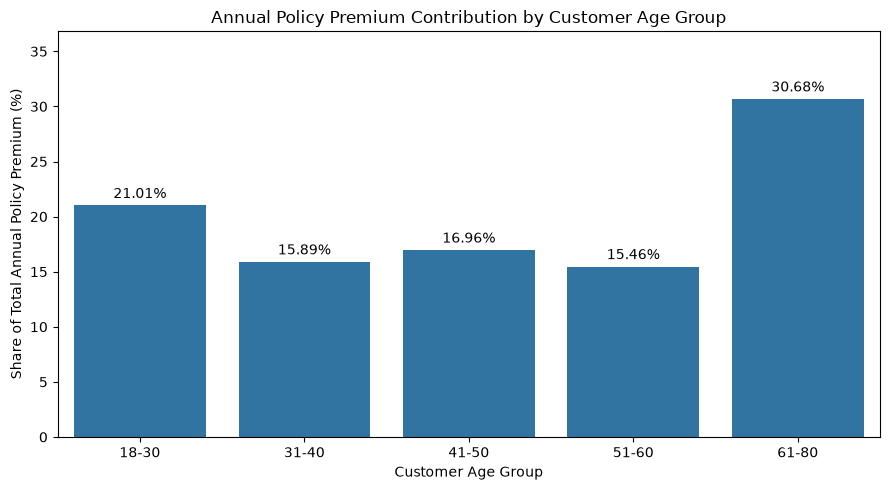

In [35]:

# Step 12.33 — Age-Based Premium Contribution Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_premium_summary,
    x="Age_Group",
    y="Premium_Share_Percent"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Annual Policy Premium Contribution by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Share of Total Annual Policy Premium (%)")

plt.ylim(0, age_premium_summary["Premium_Share_Percent"].max() * 1.2)

plt.tight_layout()
plt.show()


In [36]:

# Step 12.34 — Customer Premium Contribution by Income Group

income_premium_analysis = income_policy_analysis[
    ["Customer_ID", "Income_Group"]
].merge(
    customer_premium_analysis[
        ["Customer_ID", "Total_Annual_Premium"]
    ],
    on="Customer_ID",
    how="left"
)

income_premium_summary = (
    income_premium_analysis
    .groupby("Income_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Total_Annual_Premium=("Total_Annual_Premium", "sum"),
        Avg_Premium_Per_Customer=("Total_Annual_Premium", "mean")
    )
    .reset_index()
)

income_premium_summary["Premium_Share_Percent"] = (
    income_premium_summary["Total_Annual_Premium"]
    / income_premium_summary["Total_Annual_Premium"].sum() * 100
).round(2)

display(income_premium_summary.round(2))


,Income_Group,Total_Customers,Total_Annual_Premium,Avg_Premium_Per_Customer,Premium_Share_Percent
0,Q1 - Low,2500,85872028.11,34348.81,25.83
1,Q2 - Lower Middle,2500,80834394.84,32333.76,24.31
2,Q3 - Upper Middle,2500,83123979.40,33249.59,25.00
3,Q4 - High,2500,82672542.22,33069.02,24.86



### Key Findings — Income-Based Premium Contribution

- The lowest-income quartile (Q1) contributes the highest share of annual policy premiums at **25.83%**.
- The second income quartile (Q2) contributes the lowest share at **24.31%**.
- Q1 also has the highest average annual premium per customer at **₹34,348.81**.
- Premium contributions are relatively balanced across income quartiles, with a difference of only **1.52 percentage points** between the highest and lowest shares.

**Business Insight:** Higher customer income does not consistently correspond to higher recorded annual policy premiums in this dataset. Policy ownership, product mix, and coverage levels may provide additional context.

**Note:** Annual policy premiums are not equivalent to actual premium collections.


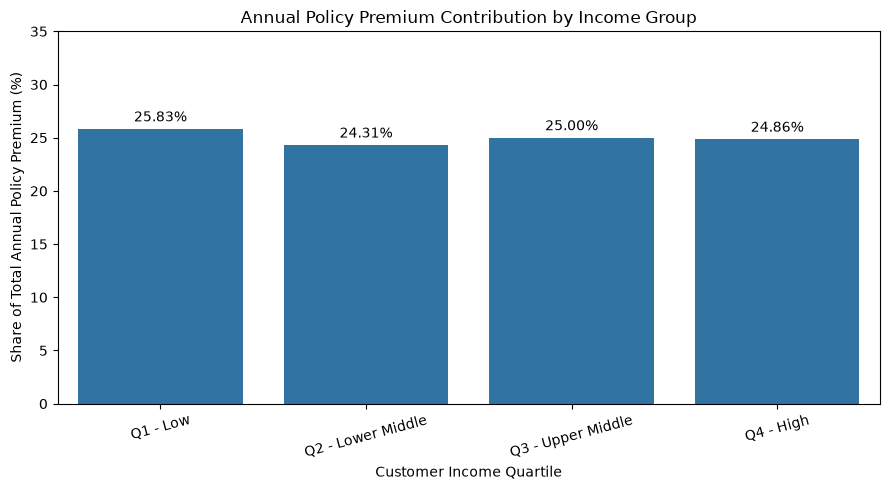

In [37]:

# Step 12.35 — Income-Based Premium Contribution Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=income_premium_summary,
    x="Income_Group",
    y="Premium_Share_Percent"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Annual Policy Premium Contribution by Income Group")
plt.xlabel("Customer Income Quartile")
plt.ylabel("Share of Total Annual Policy Premium (%)")

plt.ylim(0, 35)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [38]:

# Step 12.36 — Regional Customer Premium Contribution Analysis

regional_premium_analysis = customers[
    ["Customer_ID", "Region"]
].merge(
    customer_premium_analysis[
        ["Customer_ID", "Total_Annual_Premium"]
    ],
    on="Customer_ID",
    how="left"
)

regional_premium_summary = (
    regional_premium_analysis
    .groupby("Region")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Total_Annual_Premium=("Total_Annual_Premium", "sum"),
        Avg_Premium_Per_Customer=("Total_Annual_Premium", "mean")
    )
    .reset_index()
)

regional_premium_summary["Premium_Share_Percent"] = (
    regional_premium_summary["Total_Annual_Premium"]
    / regional_premium_summary["Total_Annual_Premium"].sum() * 100
).round(2)

regional_premium_summary = regional_premium_summary.sort_values(
    "Premium_Share_Percent",
    ascending=False
)

display(regional_premium_summary.round(2))


,Region,Total_Customers,Total_Annual_Premium,Avg_Premium_Per_Customer,Premium_Share_Percent
4,West,2029,67541005.56,33287.83,20.31
0,Central,2018,67467790.55,33433.00,20.29
1,East,1960,66004876.90,33675.96,19.85
2,North,2012,65925776.66,32766.29,19.83
3,South,1981,65563494.90,33096.16,19.72



### Key Findings — Regional Premium Contribution

- The West region contributes the highest share of annual policy premiums at **20.31%**.
- The South region contributes the lowest share at **19.72%**.
- Regional premium shares differ by only **0.59 percentage points**.
- The East region has the highest average annual premium per customer at **₹33,675.96**.

**Business Insight:** Premium contributions are relatively balanced across regions. Differences in total premiums should be evaluated alongside customer population and average premium per customer.

**Note:** These figures represent recorded annual policy premiums, not confirmed collections.


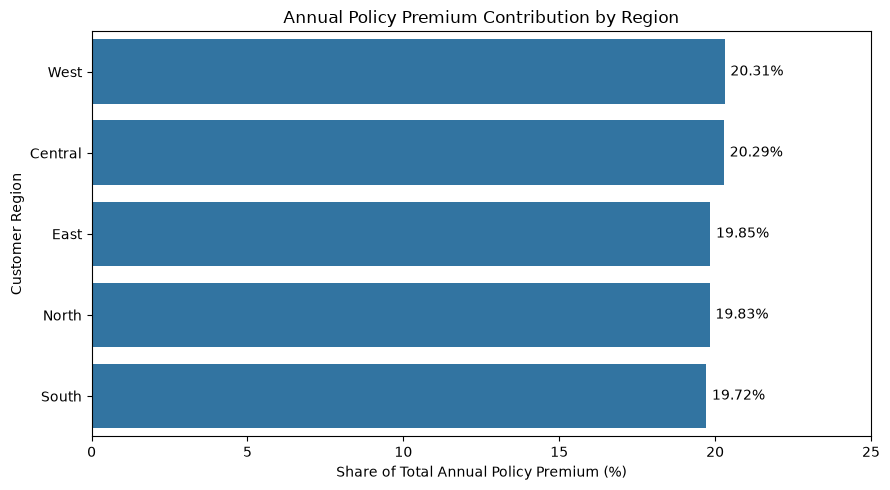

In [39]:

# Step 12.37 — Regional Premium Contribution Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=regional_premium_summary,
    x="Premium_Share_Percent",
    y="Region"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Annual Policy Premium Contribution by Region")
plt.xlabel("Share of Total Annual Policy Premium (%)")
plt.ylabel("Customer Region")

plt.xlim(0, 25)

plt.tight_layout()
plt.show()


In [40]:

# Step 12.38 — Premium Contribution by Policy Ownership

ownership_premium_analysis = customer_ownership[
    ["Customer_ID", "Ownership_Group"]
].merge(
    customer_premium_analysis[
        ["Customer_ID", "Total_Annual_Premium"]
    ],
    on="Customer_ID",
    how="left"
)

ownership_premium_summary = (
    ownership_premium_analysis
    .groupby("Ownership_Group", observed=True)
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Total_Annual_Premium=("Total_Annual_Premium", "sum"),
        Avg_Premium_Per_Customer=("Total_Annual_Premium", "mean")
    )
    .reindex(["0", "1", "2", "3", "4+"])
    .reset_index()
)

ownership_premium_summary["Premium_Share_Percent"] = (
    ownership_premium_summary["Total_Annual_Premium"]
    / ownership_premium_summary["Total_Annual_Premium"].sum() * 100
).round(2)

display(ownership_premium_summary.round(2))


,Ownership_Group,Total_Customers,Total_Annual_Premium,Avg_Premium_Per_Customer,Premium_Share_Percent
0,0,2280,0.000000e+00,0.00,0.00
1,1,3328,7.347429e+07,22077.61,22.10
2,2,2430,1.073719e+08,44185.95,32.29
3,3,1272,8.474449e+07,66623.03,25.49
4,4+,690,6.691231e+07,96974.36,20.12



### Key Findings — Premium Contribution by Policy Ownership

- Customers holding **two policies** contribute the largest share of recorded annual policy premiums at **32.29%**.
- Single-policy customers contribute **22.10%** of total annual policy premiums.
- Customers holding two or more policies collectively contribute **77.90%** of annual policy premiums.
- Average annual premium per customer increases from **₹22,077.61** for single-policy customers to **₹96,974.36** for customers holding four or more policies.
- Customers without policies contribute no recorded annual policy premiums.

**Business Insight:** Multi-policy customers account for most recorded annual policy premiums. Understanding their product combinations and retention needs may support customer portfolio management.

**Note:** These values represent recorded annual policy premiums, not confirmed collections.


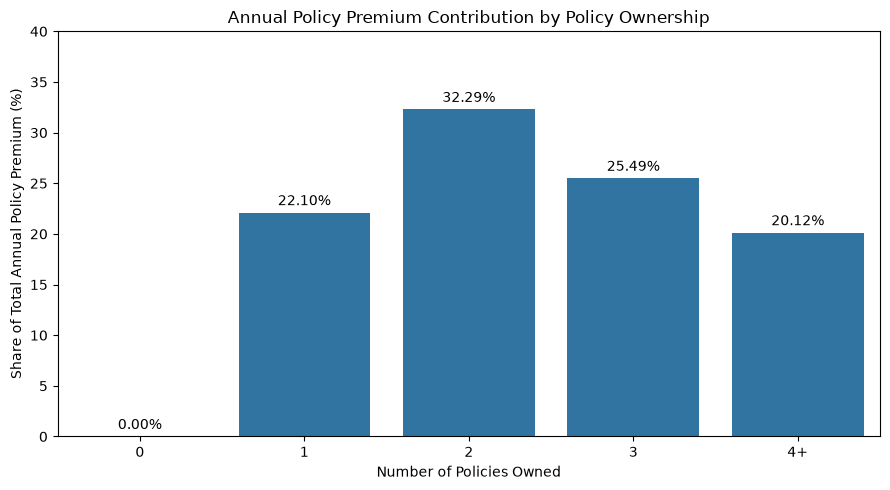

In [41]:

# Step 12.39 — Premium Contribution by Policy Ownership Visualization

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=ownership_premium_summary,
    x="Ownership_Group",
    y="Premium_Share_Percent"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Annual Policy Premium Contribution by Policy Ownership")
plt.xlabel("Number of Policies Owned")
plt.ylabel("Share of Total Annual Policy Premium (%)")

plt.ylim(0, 40)

plt.tight_layout()
plt.show()


In [42]:

# Step 12.40 — Premium Contribution by Product Diversification

diversification_premium_analysis = customer_diversification[
    ["Customer_ID", "Product_Type_Count"]
].merge(
    customer_premium_analysis[
        ["Customer_ID", "Total_Annual_Premium"]
    ],
    on="Customer_ID",
    how="left"
)

diversification_premium_summary = (
    diversification_premium_analysis
    .groupby("Product_Type_Count")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Total_Annual_Premium=("Total_Annual_Premium", "sum"),
        Avg_Premium_Per_Customer=("Total_Annual_Premium", "mean")
    )
    .reset_index()
)

diversification_premium_summary["Premium_Share_Percent"] = (
    diversification_premium_summary["Total_Annual_Premium"]
    / diversification_premium_summary["Total_Annual_Premium"].sum() * 100
).round(2)

display(diversification_premium_summary.round(2))


,Product_Type_Count,Total_Customers,Total_Annual_Premium,Avg_Premium_Per_Customer,Premium_Share_Percent
0,0,2280,0.000000e+00,0.00,0.00
1,1,4185,1.153791e+08,27569.67,34.70
2,2,2734,1.504563e+08,55031.55,45.25
3,3,734,5.922213e+07,80684.10,17.81
4,4,67,7.445498e+06,111126.84,2.24


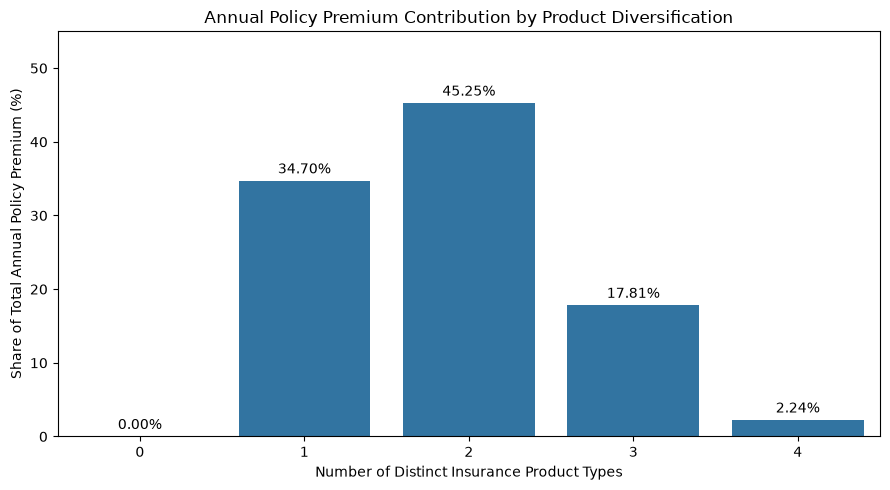

In [43]:

# Step 12.41 — Premium Contribution by Product Diversification

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=diversification_premium_summary,
    x="Product_Type_Count",
    y="Premium_Share_Percent"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Annual Policy Premium Contribution by Product Diversification")
plt.xlabel("Number of Distinct Insurance Product Types")
plt.ylabel("Share of Total Annual Policy Premium (%)")

plt.ylim(0, 55)

plt.tight_layout()
plt.show()



## Customer Analysis — Final Summary

### 1. Customer Portfolio
- Total customers analyzed: **10,000**.
- **7,720 customers (77.20%)** own at least one insurance policy.
- **4,392 customers (43.92%)** own multiple policies.
- **3,535 customers (35.35%)** own multiple insurance product types.

### 2. Customer Claim Activity
- **7,007 customers (70.07%)** have at least one recorded claim.
- Average recorded claims per customer: **2.50**.
- **2,912 customers (29.12%)** submitted four or more claims.
- These high-frequency customers account for **68.06%** of all recorded claims.

### 3. Customer Premium Contribution
- Total recorded annual policy premiums: **₹332.50 million**.
- Customers holding two or more policies contribute **77.90%** of annual policy premiums.
- Customers holding two distinct product types contribute the largest individual diversification-segment share at **45.25%**.
- The top 10% of customers by annual policy premium contribute approximately **32.80%**.

### 4. Demographic and Regional Findings
- Policy ownership and claim participation rates are relatively consistent across age groups, income quartiles, and regions.
- Customers aged **61–80** contribute the largest age-group premium share at **30.68%**, partly reflecting their larger population.
- The **West** region contributes the highest annual policy premium share at **20.31%**.
- Income quartiles contribute relatively balanced shares of annual policy premiums.

### Overall Conclusion
Customer portfolio value and claim activity are more concentrated by policy ownership and product diversification than by broad demographic or regional segments.

These findings support further investigation of multi-policy customers, customer retention opportunities, and high-frequency claim activity.

**Important:** Recorded annual policy premiums are not confirmed collections. Historical claim participation and frequency do not independently establish insurance risk or fraud.



## Business Insights & Recommendations

### 1. Strengthen Multi-Policy Customer Retention

**Finding:** Customers holding two or more policies contribute 77.90% of total recorded annual policy premiums.

**Recommendation:** Prioritize multi-policy customers for retention initiatives, renewal support, and personalized customer engagement.

### 2. Investigate High-Frequency Claim Activity

**Finding:** 29.12% of customers account for 68.06% of recorded claims.

**Recommendation:** Review high-frequency customer segments to understand claim patterns, coverage exposure, and claim severity.

High claim frequency alone should not be treated as evidence of fraud.

### 3. Identify Cross-Selling Opportunities

**Finding:** 41.85% of customers own only one insurance product type, while 35.35% own multiple product types.

**Recommendation:** Evaluate suitable cross-selling opportunities among single-product customers based on their coverage needs and eligibility.

### 4. Use Customer Value for Portfolio Management

**Finding:** The top 10% of customers by recorded annual policy premium contribute approximately 32.80% of total annual policy premiums.

**Recommendation:** Monitor high-premium customer segments and develop appropriate retention strategies while maintaining service quality across the broader customer base.

### 5. Avoid Over-Reliance on Demographic Segmentation

**Finding:** Policy ownership and claim participation rates are relatively consistent across customer age groups, income quartiles, and regions.

**Recommendation:** Combine demographic information with policy ownership, product diversification, coverage, and claim history when evaluating customer segments.

### Final Business Conclusion

Customer portfolio analysis identifies two important patterns:

1. Multi-policy customers contribute a substantial share of recorded annual policy premiums.
2. High-frequency claim customers account for a disproportionately large share of recorded claim volume.

These findings provide a foundation for customer retention planning, portfolio monitoring, cross-selling evaluation, and further claim investigation.

**Limitations:** Annual policy premiums do not represent confirmed collections. Historical claim activity does not establish fraud or underlying risk without additional exposure-adjusted analysis.
